In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Tentukan path file Excel Anda di Google Drive
# Ganti 'nama_file_anda.xlsx' dengan nama file asli Anda
file_path = '/content/drive/MyDrive/nama_file_anda.xlsx'

try:
    # Membaca file Excel menggunakan pandas
    df = pd.read_excel(file_path)
    print("Data Excel berhasil dimuat!")
    display(df.head())
except FileNotFoundError:
    print(f"File tidak ditemukan di path: {file_path}. Silakan periksa kembali path file Anda.")
except Exception as e:
    print(f"Terjadi kesalahan saat membaca file: {e}")

Week 12 — Data Visualization with Matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

print("Matplotlib:", matplotlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Matplotlib: 3.10.0
NumPy: 2.4.6
Pandas: 2.2.3


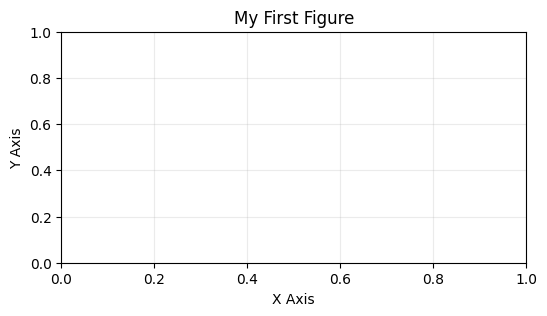

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_title("My First Figure")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
ax.grid(alpha=0.25)
plt.show()

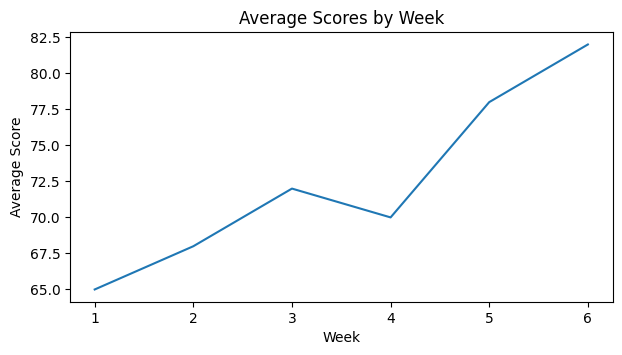

In [4]:
weeks = np.array([1, 2, 3, 4, 5, 6])
average_scores = np.array([65, 68, 72, 70, 78, 82])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, average_scores)
ax.set_title("Average Scores by Week")
ax.set_xlabel("Week")
ax.set_ylabel("Average Score")
ax.set_xticks(weeks)
plt.show()

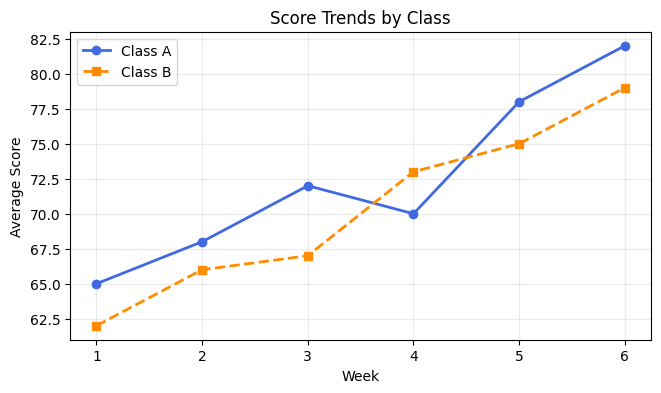

In [6]:
class_a = np.array([65, 68, 72, 70, 78, 82])
class_b = np.array([62, 66, 67, 73, 75, 79])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(weeks, class_a, color="royalblue", marker="o", linewidth=2, label="Class A")
ax.plot(weeks, class_b, color="darkorange", marker="s", linestyle="--", linewidth=2, label="Class B")
#ax set bisa digabung
ax.set(title="Score Trends by Class", xlabel="Week", ylabel="Average Score")
ax.set_xticks(weeks)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

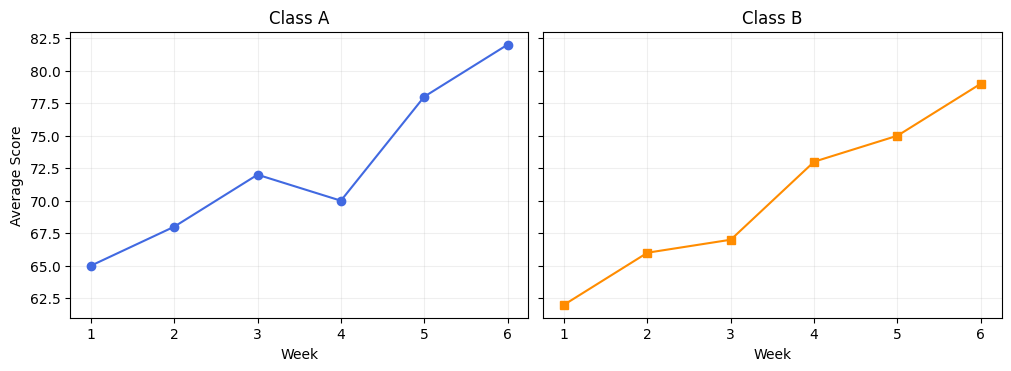

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout="constrained")
axes[0].plot(weeks, class_a, marker="o", color="royalblue")
axes[0].set(title="Class A", xlabel="Week", ylabel="Average Score")

axes[1].plot(weeks, class_b, marker="s", color="darkorange")
axes[1].set(title="Class B", xlabel="Week")
for ax in axes:
    ax.set_xticks(weeks)
    ax.grid(alpha=0.2)
plt.show()

In [9]:
dates = pd.date_range(start="2026-01-01", periods=12, freq="MS")
rainfall = np.array([245, 218, 230, 275, 310, 185, 145, 125, 165, 235, 290, 265])
temperature = np.array([27.5, 27.8, 28.0, 28.2, 28.1, 28.6, 28.8, 29.0, 28.9, 28.4, 28.0, 27.7])
# dates menjadi index
weather = pd.DataFrame({"Rainfall_mm": rainfall, "Temperature_C": temperature}, index=dates)
weather.index.name = "Date"

print("\nIndex type:", type(weather.index).__name__)
print(weather)


Index type: DatetimeIndex
            Rainfall_mm  Temperature_C
Date                                  
2026-01-01          245           27.5
2026-02-01          218           27.8
2026-03-01          230           28.0
2026-04-01          275           28.2
2026-05-01          310           28.1
2026-06-01          185           28.6
2026-07-01          145           28.8
2026-08-01          125           29.0
2026-09-01          165           28.9
2026-10-01          235           28.4
2026-11-01          290           28.0
2026-12-01          265           27.7


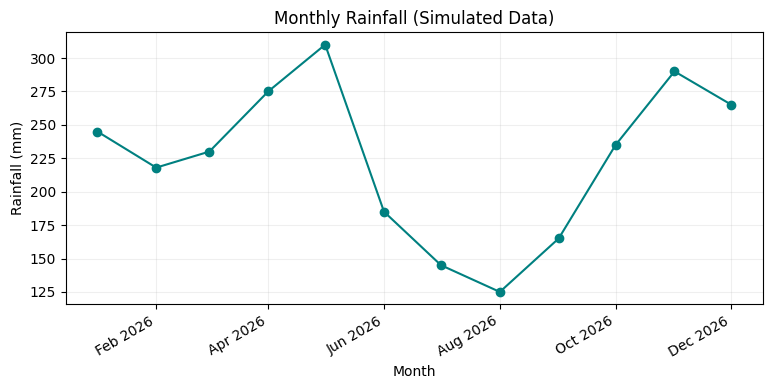

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

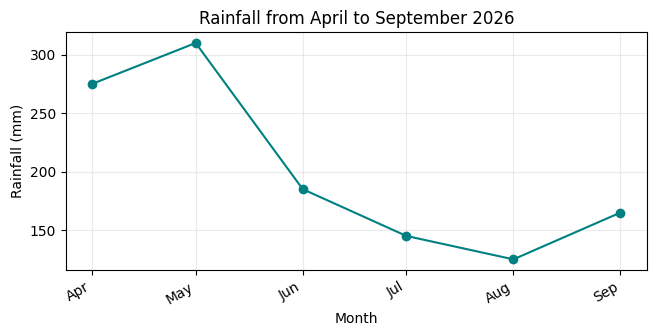

In [11]:
selected_period = weather.loc["2026-04":"2026-09"]

fig, ax = plt.subplots(figsize=(7.5, 3.5))
# disini letak selected period nya
ax.plot(selected_period.index, selected_period["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Rainfall from April to September 2026", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)

fig.autofmt_xdate()
plt.show()

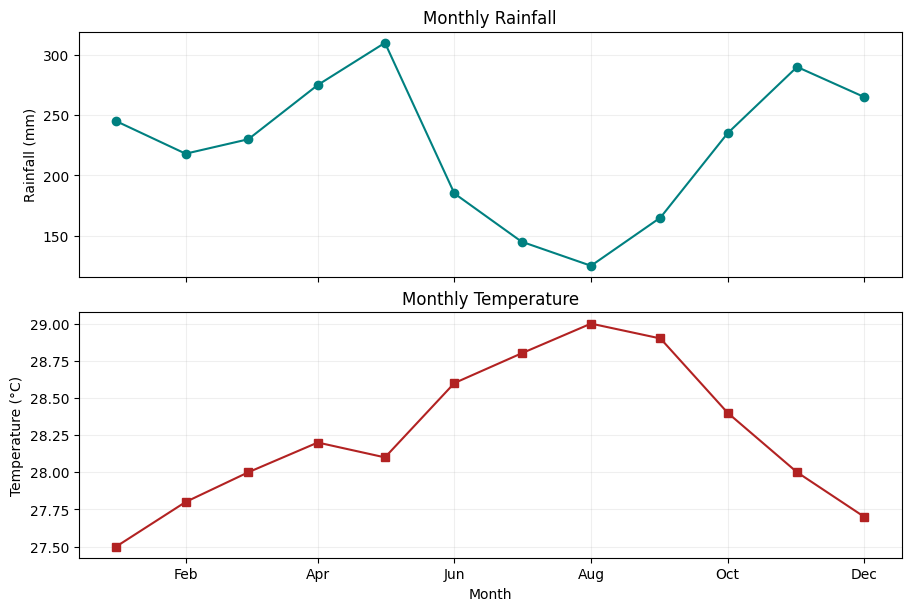

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
axes[0].plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
axes[0].set(title="Monthly Rainfall", ylabel="Rainfall (mm)")

axes[1].plot(weather.index, weather["Temperature_C"], marker="s", color="firebrick")
axes[1].set(title="Monthly Temperature", xlabel="Month", ylabel="Temperature (°C)")

axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()


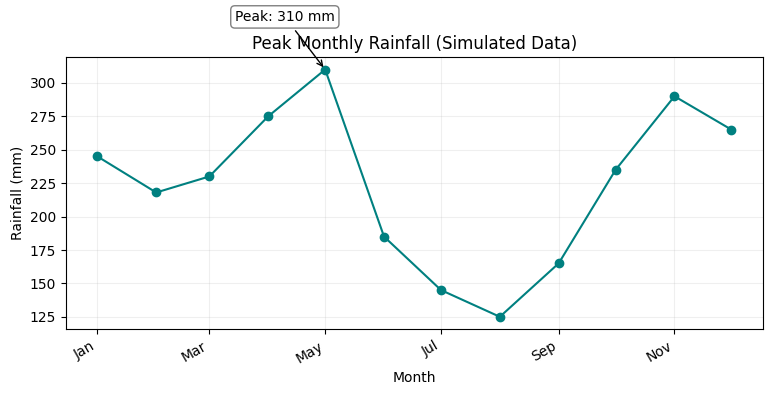

In [14]:
peak_date = weather["Rainfall_mm"].idxmax()
peak_value = weather["Rainfall_mm"].max()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.annotate(f"Peak: {peak_value} mm",
            xy=(peak_date, peak_value), xytext=(-65, 35),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": "black"},
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "gray"})
ax.set(title="Peak Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

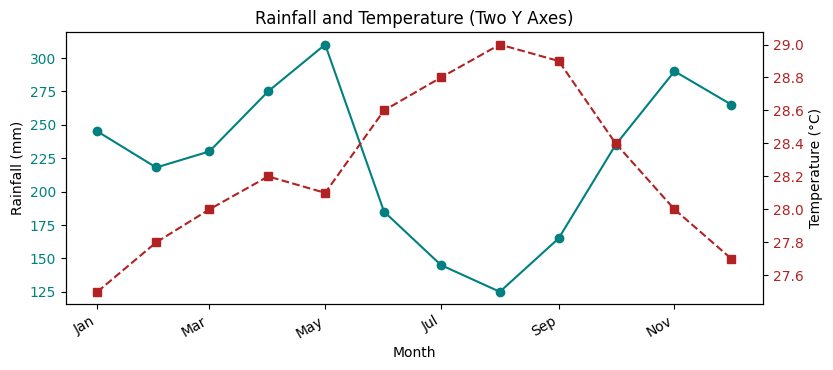

In [15]:
fig, ax1 = plt.subplots(figsize=(9, 4))

ax2 = ax1.twinx()

ax1.plot(weather.index, weather["Rainfall_mm"], color="teal", marker="o", label="Rainfall")
ax2.plot(weather.index, weather["Temperature_C"], color="firebrick", marker="s", linestyle="--", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Month", ylabel="Rainfall (mm)")
ax2.set_ylabel("Temperature (°C)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()

In [16]:
rng = np.random.default_rng(12)
scores_a = np.clip(rng.normal(loc=78, scale=8, size=40), 0, 100)
scores_b = np.clip(rng.normal(loc=72, scale=10, size=40), 0, 100)
print("Class A: n =", len(scores_a), ", mean =", round(scores_a.mean(), 2))
print("Class B: n =", len(scores_b), ", mean =", round(scores_b.mean(), 2))

Class A: n = 40 , mean = 77.99
Class B: n = 40 , mean = 72.93


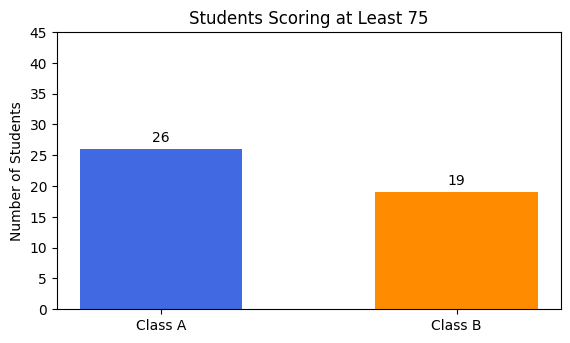

In [17]:
categories = ["Class A", "Class B"]
pass_counts = np.array([(scores_a >= 75).sum(), (scores_b >= 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(categories, pass_counts, color=["royalblue", "darkorange"], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Students Scoring at Least 75", ylabel="Number of Students")
ax.set_ylim(0, len(scores_a) + 5)
plt.show()

In [18]:
pass_counts

array([26, 19])

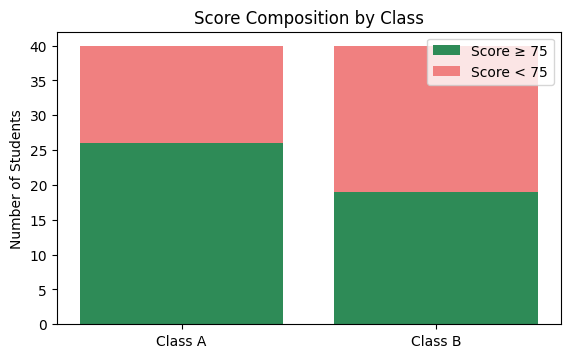

In [19]:
below_counts = np.array([(scores_a < 75).sum(), (scores_b < 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.bar(categories, pass_counts, label="Score ≥ 75", color="seagreen")
ax.bar(categories, below_counts, bottom=pass_counts, label="Score < 75", color="lightcoral")
ax.set(title="Score Composition by Class", ylabel="Number of Students")

ax.legend()
plt.show()

In [20]:
below_counts

array([14, 21])

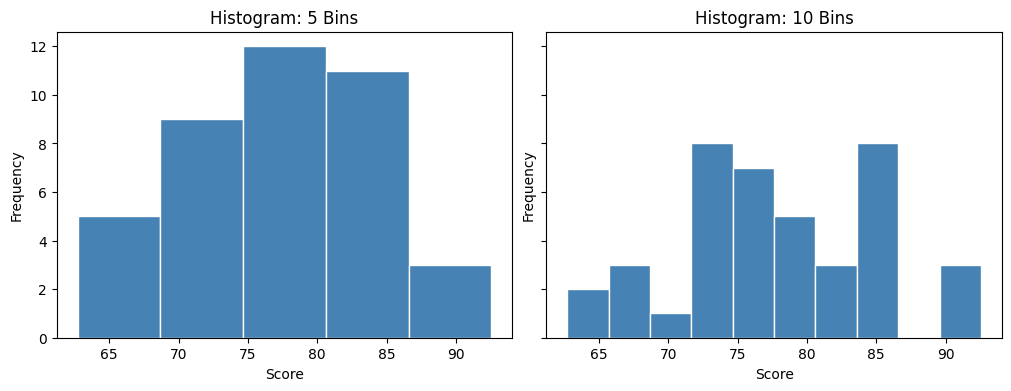

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [5, 10]):
    ax.hist(scores_a, bins=n_bins, color="steelblue", edgecolor="white")
    ax.set(title=f"Histogram: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()

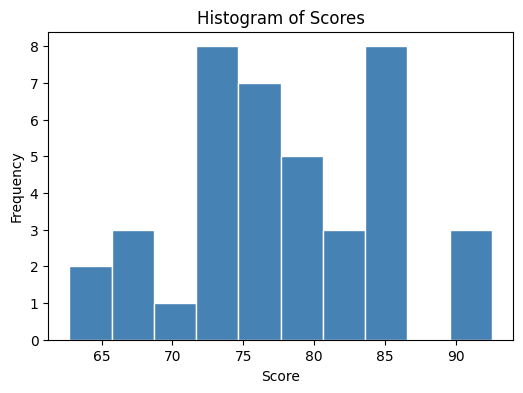

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(
    scores_a,
    bins=10,
    color="steelblue",
    edgecolor="white"
)
ax.set(
    title="Histogram of Scores",
    xlabel="Score",
    ylabel="Frequency"
)
plt.show()

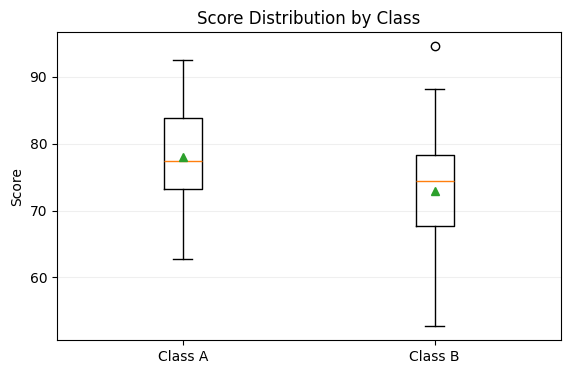

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 4))
# segitiga adalah means jika showmeans true
ax.boxplot([scores_a, scores_b], showmeans=True)
ax.set_xticks([1, 2], categories)
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

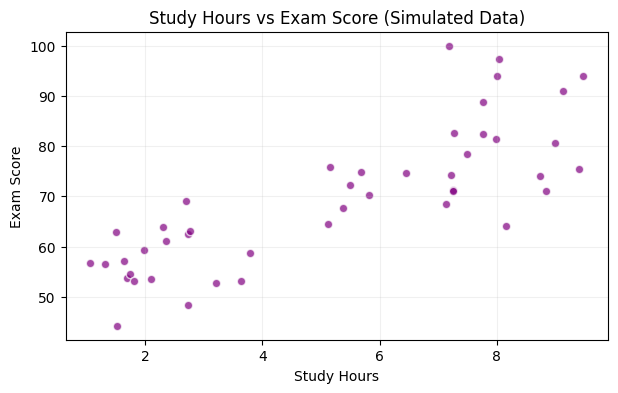

Pearson correlation: 0.81


In [24]:
# buat data baru
study_hours = rng.uniform(1, 10, size=45)
exam_scores = np.clip(48 + 4.3 * study_hours + rng.normal(0, 9, size=45), 0, 100)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)

plt.show()
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))

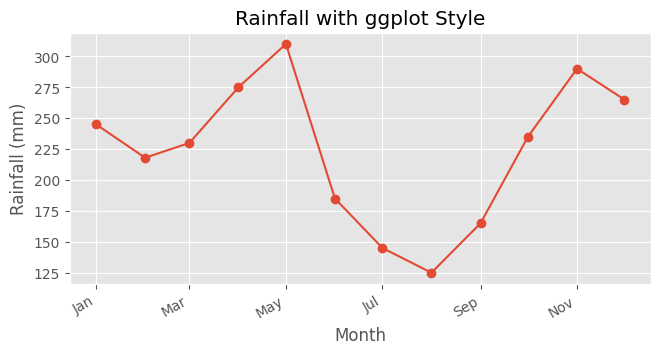

In [28]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()


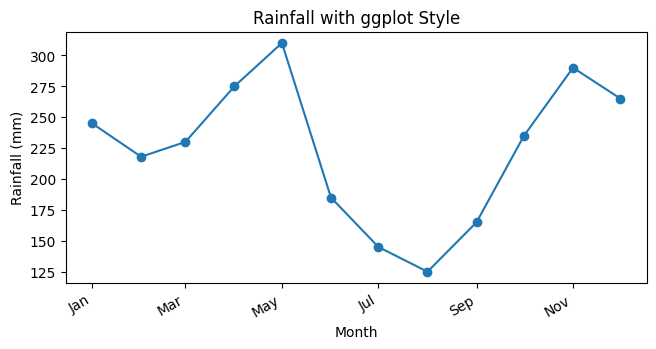

In [46]:
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()

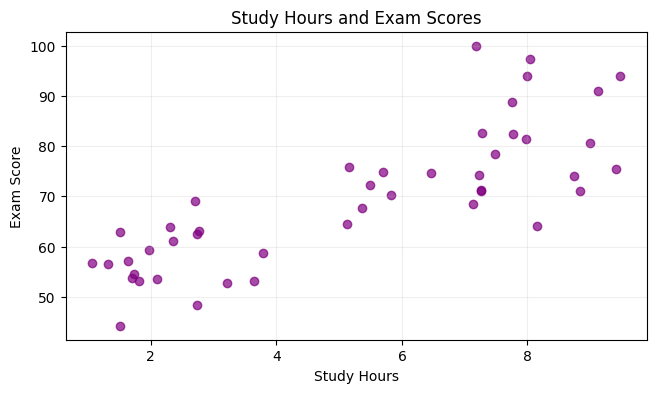

Saved to: /content/week12_figures


In [47]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(study_hours, exam_scores, alpha=0.7, color="purple")
ax.set(title="Study Hours and Exam Scores", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "week12_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.pdf", bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.svg", bbox_inches="tight")
plt.show()
print("Saved to:", output_dir.resolve())

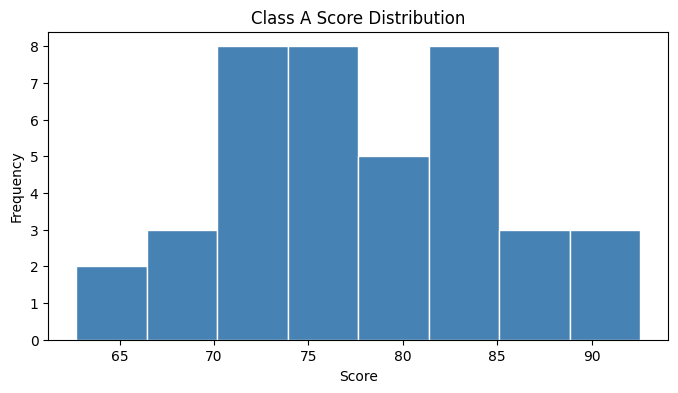

File: week12_figures/week12_histogram_300dpi.png
File size: 53.2 KB


In [48]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores_a, bins=8, edgecolor="white", color="steelblue")
ax.set(title="Class A Score Distribution", xlabel="Score", ylabel="Frequency")
file_path = output_dir / "week12_histogram_300dpi.png"
fig.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()
print("File:", file_path)
print("File size:", round(file_path.stat().st_size / 1024, 1), "KB")

In [49]:
for name in ["week12_scatter.png", "week12_scatter.pdf", "week12_scatter.svg",
             "week12_histogram_300dpi.png"]:
    path = output_dir / name
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

week12_scatter.png: Found
week12_scatter.pdf: Found
week12_scatter.svg: Found
week12_histogram_300dpi.png: Found


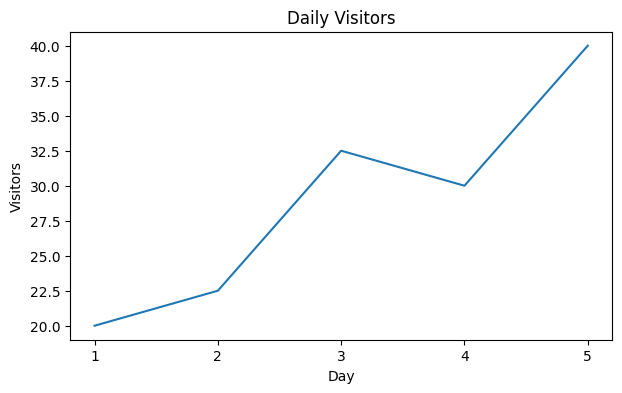

In [64]:
import matplotlib.pyplot as plt

days = [1, 2, 3, 4, 5]
visitors = [20.0, 22.5, 32.5, 30.0, 40.0]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(days, visitors)
ax.set_title("Daily Visitors")
ax.set_xlabel("Day")
ax.set_ylabel("Visitors")
ax.set_xticks(weeks)
plt.show()

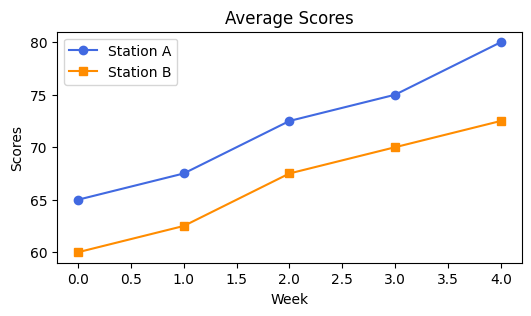

In [63]:
import pandas as pd
import matplotlib.dates as mdates

station_a = [65.0, 67.5, 72.5, 75.0, 80.0]
station_b = [60.0, 62.5, 67.5, 70.0, 72.5]

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot( station_a, color='royalblue', marker='o', label='Station A')
ax.plot( station_b, color='darkorange', marker='s', label='Station B')

ax.set_title("Average Scores")
ax.set_xlabel("Week")
ax.set_ylabel("Scores")

ax.legend()
plt.show()

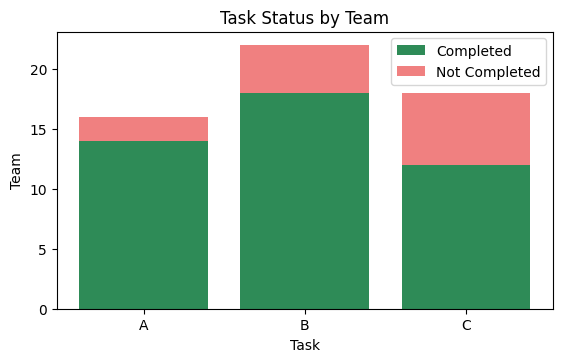

In [40]:
team = np.array (["A","B","C"])
completed = np.array([14, 18, 12])
not_completed = np.array([2,4,6])

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.bar(team, completed, color="seagreen", label="Completed")
ax.bar(team, not_completed, bottom=completed, label="Not Completed", color="lightcoral")
ax.set(title="Task Status by Team", xlabel = "Task", ylabel="Team")
ax.legend()
plt.show()

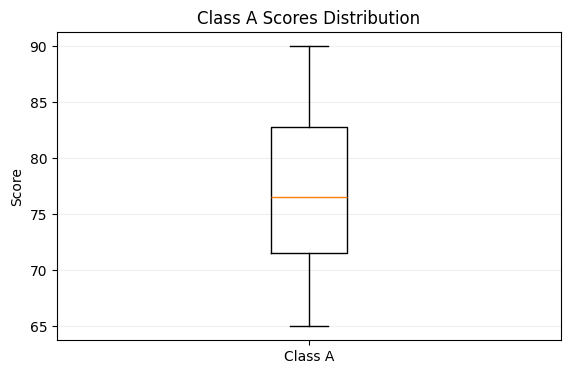

In [62]:
scores = np.array ([65, 68, 70, 72, 74, 75, 78, 80, 82, 85, 87, 90])
fig, ax = plt.subplots(figsize=(6.5, 4))
# segitiga adalah means jika showmeans true
ax.boxplot(scores)
ax.set_xticks([1], ["Class A"])
ax.set(title="Class A Scores Distribution", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

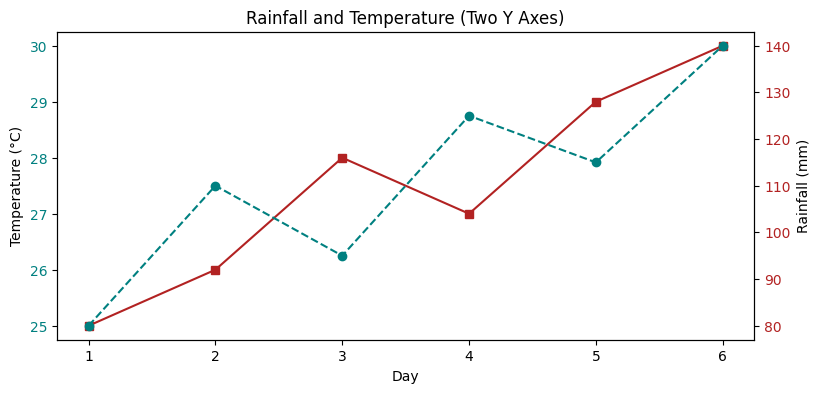

In [61]:
fig, ax1 = plt.subplots(figsize=(9, 4))

day = np.array([1, 2, 3, 4, 5, 6])
temperature = np.array([25, 26, 28, 27, 29, 30])
rainfall = np.array([80, 110, 95, 125, 115, 140])

ax2 = ax1.twinx()

ax2.plot(day, rainfall, color="teal", marker="o",linestyle="--", label="Rainfall")
ax1.plot(day, temperature, color="firebrick", marker="s", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Day", ylabel="Temperature (°C)")
ax2.set_ylabel("Rainfall (mm)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.set_xticks(day)
plt.show()